# 05 · Sequence models

The slice models of 04 see one slice and its two neighbours. A series holds 16–60 slices (one per position, 02), and a bleed usually spans several of them. A second model reads the slice model's predictions along the whole series and corrects them.

**Contents**
1. Setting up the sequence model
2. Choosing what it reads from the slice model
3. Combining the two backbones
4. Trying other networks and augmentation
5. Training on five folds
6. Setting the temperature
7. Predicting the test set

No model is trained here: the runs were made with `scripts/train_sequence.py` and `scripts/fit_temperature.py`, and the notebook reads their saved predictions. Needs `slices.csv` (02), the outputs of the slice models of 04 in `outputs/features/` and the runs in `outputs/seq_runs/`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ich.data.prepare import LABELS, read_table
from ich.metrics import image_losses, paired_bootstrap, score
from ich.paths import load_paths
from ich.submission import check_submission, to_submission

pd.set_option("display.width", 200)

paths = load_paths()
DATA_DIR, PROCESSED, OUTPUTS = paths["raw_data_dir"], paths["processed_data_dir"], paths["outputs_dir"]
FEATURES, SEQ = OUTPUTS / "features", OUTPUTS / "seq_runs"

table = read_table(PROCESSED / "slices.csv")
position_labels = table[table["split"] == "train"].set_index("image")[LABELS].astype(float)  # labels of a kept slice's position (02, 3.1)
BACKBONES = {"cx": "convnext_tiny", "mv": "mobilevitv2_175"}
COLORS = {"cx": "tab:blue", "mv": "tab:orange"}


def cnn_run(backbone, fold):
    # The slice model of 04 for one backbone and fold: fold 0 is the run of 04, 7.2, folds 1-4 those of 04, 8.
    return f"b3_512_{backbone}" if fold == 0 else f"c_{backbone}_f{fold}"


# fold 0: the validation slices of the fold-0 slice models, the same in every fold-0 run
val = pd.read_csv(FEATURES / cnn_run("convnext_tiny", 0) / "oof_images.csv")
assert pd.read_csv(FEATURES / cnn_run("mobilevitv2_175", 0) / "oof_images.csv")["image"].equals(val["image"])
kept = val["keep"].to_numpy()
y = position_labels.loc[val["image"][kept]].to_numpy()
groups = table.set_index("image").loc[val["image"][kept], "patient"].to_numpy()
test_images = pd.read_csv(FEATURES / cnn_run("convnext_tiny", 0) / "test_images.csv")["image"]
print(f"fold 0: {len(val):,} slices ({kept.sum():,} kept), {len(set(groups)):,} patients | test: {len(test_images):,} slices")

fold 0: 150,537 slices (149,017 kept), 3,787 patients | test: 121,232 slices


In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def cnn_probs(backbone, fold=0, part="oof"):
    # The slice model's probabilities: the validation fold ("oof", kept slices) or the test set.
    p = sigmoid(np.load(FEATURES / cnn_run(backbone, fold) / f"{part}_logits.npy"))
    return p[kept] if part == "oof" else p


def seq_probs(prefix, part="val", tta=False, seeds=3):
    # Mean probability of the seeds of a sequence model (runs PREFIX_s0, _s1, ...) on the fold-0 kept slices ("val") or
    # the test set ("test"); tta: averaged with the prediction of the reversed series (section 4).
    ps = []
    for s in range(seeds):
        d = SEQ / f"{prefix}_s{s}"
        if part == "val":
            assert pd.read_csv(d / "val.csv")["image"].equals(val["image"]), d
        elif (d / "test.csv").exists():  # the oldest runs predict the test slices in the order of test_images.csv
            assert pd.read_csv(d / "test.csv")["image"].equals(test_images), d
        p = np.load(d / f"{part}_probs.npy")
        ps.append((p + np.load(d / f"{part}_rev_probs.npy")) / 2 if tta else p)
    p = np.mean(ps, 0)
    return p[kept] if part == "val" else p


def late(run, part="val", tta=False):
    # Late ensemble: the mean of the two backbones' sequence models (section 3).
    return (seq_probs(run.format(b="cx"), part, tta) + seq_probs(run.format(b="mv"), part, tta)) / 2


def difference(p_from, p_to):
    # Score of p_to minus that of p_from on the kept fold-0 slices: mean and 95% interval of a patient bootstrap (03, 6).
    return paired_bootstrap(image_losses(y, p_from), image_losses(y, p_to), groups)


def interval(d):
    return f"{d['mean']:+.4f} [{d['low']:+.4f}, {d['high']:+.4f}]"


def entropy(p):
    # Mean binary entropy of the predictions: how far they are from 0 and 1 on average (lower = more confident).
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(np.mean(-p * np.log(p) - (1 - p) * np.log(1 - p)))


def compare(p):
    # Fold-0 score of each prediction and its difference to the first one.
    ref = next(iter(p))
    rows = [{"": name, "score": round(score(y, v), 4), f"− {ref}": "" if name == ref else interval(difference(p[ref], v))}
            for name, v in p.items()]
    return pd.DataFrame(rows).set_index("")

## 1. Setting up the sequence model

Each slice model of 04 was trained on four folds and never saw the fifth. Its sequence model is trained on what that slice model outputs on the same four folds, and both are scored only on the fifth, so neither has seen the slices it is scored on. Nothing inside a run is chosen on the scored fold either: the model after the last epoch is kept, and the temperature (section 6) comes from the training folds. Which input, ensemble and network to use (sections 2–4) was decided on fold 0, as in 04.

The sequence model reads one series at a time: its kept slices (02) in order, 16–60 of them. The other slices of a position, which the test set keeps (02), get the prediction of its kept slice. A bidirectional GRU (BiGRU) reads the six logits of each slice, and its output is added to those logits (a residual head). That last layer starts at zero, so the untrained model returns exactly the slice model's predictions and training learns only a correction.

| Part | Setup |
|---|---|
| input | the six logits of the slice model per slice |
| network | BiGRU, 2 layers, 256 units per direction (1.6 M parameters) |
| training | competition loss on the real slices, AdamW 1e-3, 10 epochs, batch 64 series |
| seeds | 3 per setup, probabilities averaged |

The command of the base run (convnext_tiny, fold 0), and the gap the sequence model learns across: the slice model on its four training folds against its held-out fold:

In [3]:
c = json.loads((SEQ / "is_cx_logits_f0_s0" / "config.json").read_text())
print(f"python scripts/train_sequence.py --name is_cx_logits_f0_s0 --cnn {' '.join(c['cnn'])} --inputs logits")

rows = []
for backbone in BACKBONES.values():
    train_images = pd.read_csv(FEATURES / cnn_run(backbone, 0) / "train_images.csv")
    k = train_images["keep"].to_numpy()
    p_train = sigmoid(np.load(FEATURES / cnn_run(backbone, 0) / "train_logits.npy"))[k]
    s_train = score(position_labels.loc[train_images["image"][k]].to_numpy(), p_train)
    rows.append({"": backbone, "score, training folds": s_train, "score, held-out": score(y, cnn_probs(backbone)),
                 "ratio": s_train / score(y, cnn_probs(backbone)),
                 "entropy, training folds": entropy(p_train), "entropy, held-out": entropy(cnn_probs(backbone))})
pd.DataFrame(rows).set_index("").round({"score, training folds": 4, "score, held-out": 4, "ratio": 2,
                                        "entropy, training folds": 4, "entropy, held-out": 4})

python scripts/train_sequence.py --name is_cx_logits_f0_s0 --cnn b3_512_convnext_tiny --inputs logits


,"score, training folds","score, held-out",ratio,"entropy, training folds","entropy, held-out"
,,,,,
convnext_tiny,0.0409,0.0628,0.65,0.0403,0.0423
mobilevitv2_175,0.0482,0.0620,0.78,0.0487,0.0506


On its training folds the slice model scores 0.65–0.78 of its held-out loss with an entropy only about 4% lower: it is right more often there, and barely more confident. Three series of fold 0 with a bleed, before and after the sequence model (convnext_tiny):

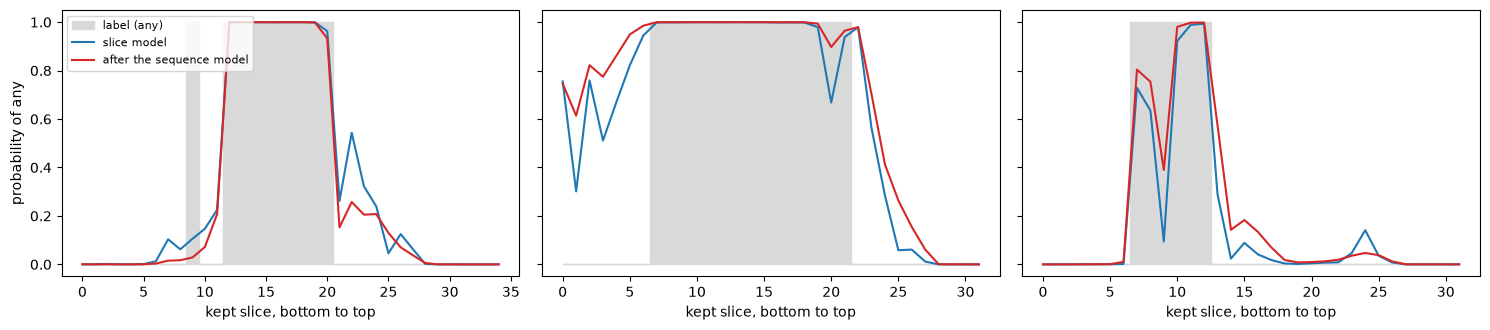

In [4]:
cnn_all = sigmoid(np.load(FEATURES / cnn_run("convnext_tiny", 0) / "oof_logits.npy"))
seq_all = np.load(SEQ / "is_cx_logits_f0_s0" / "val_probs.npy")
info = table.set_index("image").loc[val["image"], ["series", "slice", "any"]].reset_index(drop=True).assign(keep=kept)
bleeding = info[info["keep"]].groupby("series").agg(n=("slice", "size"), bleed=("any", "sum"))
candidates = bleeding[(bleeding["n"] >= 30) & (bleeding["bleed"].between(4, 15))].index
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for ax, series in zip(axes, np.random.default_rng(0).choice(candidates, 3, replace=False)):
    rows = info[(info["series"] == series) & info["keep"]].sort_values("slice").index
    x = np.arange(len(rows))
    ax.fill_between(x, 0, info.loc[rows, "any"], step="mid", color="0.85", label="label (any)")
    ax.plot(x, cnn_all[rows, -1], color="tab:blue", label="slice model")
    ax.plot(x, seq_all[rows, -1], color="tab:red", label="after the sequence model")
    ax.set_xlabel("kept slice, bottom to top")
axes[0].set_ylabel("probability of any")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

## 2. Choosing what it reads from the slice model

Before its last layer a slice model pools its feature map into one vector per slice, its features (768 values for convnext_tiny, 896 for mobilevitv2_175). The sequence model can read the six logits, the vector (LayerNorm, a projection to 256 values, dropout 0.3), or both. The vector may carry what the slice model memorised of its training slices, so two narrower paths were tried as well (dropout 0.4): a projection to 128 / 256 / 512 values, and two branches (a first BiGRU predicts the labels from the vector alone with its own loss, a second reads the logits and that prediction). Out of fold on fold 0:

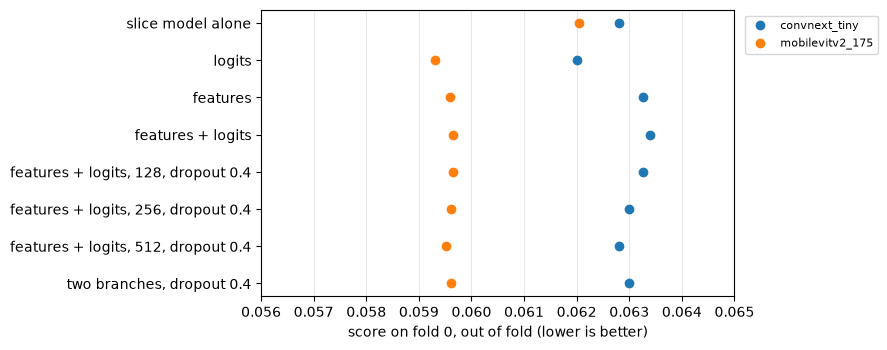

test entropy, slice model → logits: convnext_tiny 0.037 → 0.031, mobilevitv2_175 0.045 → 0.035


convnext_tiny 1×1 (one slice, 04, 7.2), features + logits: 0.0614 against 3×1 0.0634 | 1×1 slice model alone 0.0652


In [5]:
INPUTS = {"slice model alone": None, "logits": "is_{b}_logits_f0", "features": "e5_{e}_3x1_featonly",
          "features + logits": "e5_{e}_3x1", **{f"features + logits, {n}, dropout 0.4": f"q4_gru_p{n}_{{b}}_f0" for n in (128, 256, 512)},
          "two branches, dropout 0.4": "q4_gru_branch_{b}_f0"}


def input_probs(name, b, part="val"):
    if INPUTS[name] is None:
        return cnn_probs(BACKBONES[b], part="oof" if part == "val" else part)
    run = INPUTS[name].format(b=b, e={"cx": "convnext", "mv": "mobilevit"}[b])
    return seq_probs("e5_mobilevit_3x1_features" if run == "e5_mobilevit_3x1" else run, part)  # longer name of that run


oof2 = {b: {name: score(y, input_probs(name, b)) for name in INPUTS} for b in BACKBONES}
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(len(INPUTS))[::-1]
for b, backbone in BACKBONES.items():
    ax.plot(list(oof2[b].values()), pos, "o", color=COLORS[b], label=backbone)
ax.set_yticks(pos, list(INPUTS))
ax.set_xlim(0.056, 0.065)
ax.set_xlabel("score on fold 0, out of fold (lower is better)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
print("test entropy, slice model → logits:",
      ", ".join(f"{bb} {entropy(input_probs('slice model alone', b, 'test')):.3f} → {entropy(input_probs('logits', b, 'test')):.3f}"
                for b, bb in BACKBONES.items()))
print(f"convnext_tiny 1×1 (one slice, 04, 7.2), features + logits: {score(y, seq_probs('e5_convnext_1x1')):.4f} "
      f"against 3×1 {oof2['cx']['features + logits']:.4f} | 1×1 slice model alone {score(y, sigmoid(np.load(FEATURES / 'b3_512_convnext_tiny_1x1' / 'oof_logits.npy'))[kept]):.4f}")

### 2.1 Key findings

- **The logits alone are the best input on both backbones:** the sequence model on them beats the slice model by 0.0008 (convnext_tiny) and 0.0027 (mobilevitv2_175).
- **The vector does not help, whatever the path:** with or without the logits, projected to 128–512 values or in its own branch, it stays behind the logits alone, by up to 0.0014 for convnext_tiny and 0.0004 for mobilevitv2_175.
- **The sequence model makes the test predictions more confident** (entropy 0.037 → 0.031 and 0.045 → 0.035). The slice model is barely more confident on its training folds (section 1), but it is right more often there, and the sequence model learns from those outputs: out of fold it is overconfident (section 6).
- The 1×1 slice model of 04 with the sequence model beats 3×1 on features + logits (0.0614 against 0.0634). It exists only for fold 0, was not run on the logits alone and was not taken further.

## 3. Combining the two backbones

The two slice models of a fold can be combined in two ways. In the **early** ensemble one sequence model reads both side by side (12 logits, or the two vectors). In the **late** ensemble each backbone has its own sequence model, and their probabilities are averaged with nothing fitted. Both against the mean of the two slice models:

In [6]:
compare({"mean of the two slice models": (cnn_probs("convnext_tiny") + cnn_probs("mobilevitv2_175")) / 2,
         "early, logits": seq_probs("e5_ens_3x1_logits"), "early, features": seq_probs("e5_ens_3x1_featonly"),
         **{f"late, {name}": (input_probs(name, "cx") + input_probs(name, "mv")) / 2
            for name in ["logits", "features", "features + logits"]}})

,score,− mean of the two slice models
,,
mean of the two slice models,0.0592,
"early, logits",0.0636,"+0.0044 [+0.0032, +0.0057]"
"early, features",0.0640,"+0.0048 [+0.0036, +0.0061]"
"late, logits",0.0576,"-0.0016 [-0.0022, -0.0010]"
"late, features",0.0579,"-0.0013 [-0.0019, -0.0007]"
"late, features + logits",0.0580,"-0.0013 [-0.0018, -0.0006]"


### 3.1 Key findings

- **Late beats early by far:** early is 0.0044–0.0048 worse than even the mean of the two slice models, late 0.0013–0.0016 better. A likely reason: each slice model fits its training folds much better than new slices (section 1), each in its own way, so what one model learns about weighing them does not hold on new slices.
- The late ensemble of the logits models is the base of the following sections.

## 4. Trying other networks and augmentation

This section starts from the late ensemble of the logits models (section 3) on fold 0 and changes one thing at a time.

### 4.1 The network

Three other networks replace the BiGRU, each with about 1.6 M parameters. The BiLSTM uses LSTM cells with 224 units per direction. The TCN stacks 8 residual blocks of dilated convolutions over the slices (dilations 1 to 32), so every slice sees the whole series. The transformer has 2 self-attention layers with a learned bias for the distance between two slices, and a lower learning rate (3e-4). The tests in `tests/test_sequence_model.py` check that each network, untrained, returns the slice model's predictions and ignores padding. Different networks may make different errors, so the means of the BiGRU with the others are shown as well. The difference of each to the BiGRU:

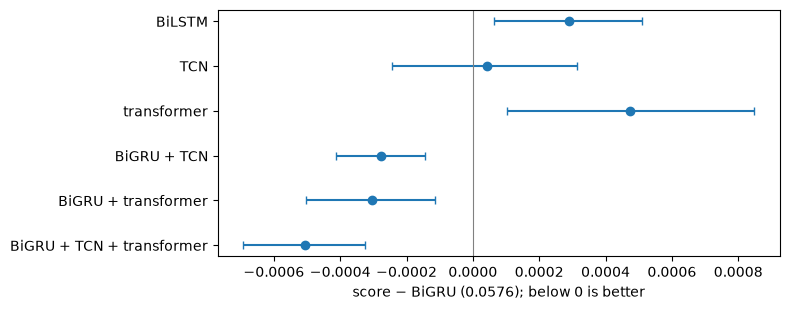

In [7]:
def forest(ax, rows, label=None, color="tab:blue", shift=0.0):
    # Difference to a reference with its 95% interval, one row per setup, top to bottom.
    pos = np.arange(len(rows))[::-1] + shift
    ax.errorbar([r["mean"] for r in rows.values()], pos, fmt="o", capsize=3, color=color, label=label,
                xerr=[[r["mean"] - r["low"] for r in rows.values()], [r["high"] - r["mean"] for r in rows.values()]])
    ax.axvline(0, color="0.5", lw=0.8)
    ax.set_yticks(np.arange(len(rows))[::-1], list(rows))


base = late("is_{b}_logits_f0")
tcn, transformer = late("q5_tcn_{b}_f0"), late("q5_transformer_{b}_f0")
NETWORKS = {"BiLSTM": late("q5_lstm_{b}_f0"), "TCN": tcn, "transformer": transformer,
            "BiGRU + TCN": (base + tcn) / 2, "BiGRU + transformer": (base + transformer) / 2,
            "BiGRU + TCN + transformer": (base + tcn + transformer) / 3}
d_net = {name: difference(base, p) for name, p in NETWORKS.items()}
fig, ax = plt.subplots(figsize=(8, 3.2))
forest(ax, d_net)
ax.set_xlabel(f"score − BiGRU ({score(y, base):.4f}); below 0 is better")
plt.tight_layout()
plt.show()

The BiGRU stays the network of the sequence model. The TCN is taken on as a second network: alone it ties with the BiGRU, while the transformer is worse, and the mean of the BiGRU and the TCN gains as much as with the transformer. The BiLSTM is dropped, and the third network adds too little to train it on five folds.

### 4.2 Augmenting the series

The sequence models so far see every training series the same way in every epoch. Two changes to a training series, each drawn with probability 0.5: reversing it (the slices in the opposite order) and subsampling it (every other slice kept). Reverse TTA averages the prediction of each series with that of the same series reversed. Each for the BiGRU and the TCN, against the same network without augmentation:

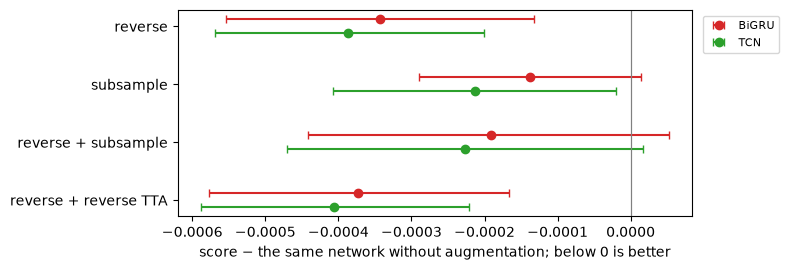

BiGRU + TCN, both with reverse and reverse TTA: 0.0571 | − BiGRU: -0.0005 [-0.0007, -0.0003]


In [8]:
AUGMENTATIONS = {"reverse": ("rev", False), "subsample": ("sub", False), "reverse + subsample": ("revsub", False),
                 "reverse + reverse TTA": ("rev", True)}
fig, ax = plt.subplots(figsize=(8, 2.8))
for arch, ref, color, shift in [("gru", base, "tab:red", 0.12), ("tcn", tcn, "tab:green", -0.12)]:
    d_aug = {name: difference(ref, late(f"aug_{arch}_{code}_{{b}}_f0", tta=tta)) for name, (code, tta) in AUGMENTATIONS.items()}
    forest(ax, d_aug, {"gru": "BiGRU", "tcn": "TCN"}[arch], color, shift)
ax.set_xlabel("score − the same network without augmentation; below 0 is better")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()
chosen = (late("aug_gru_rev_{b}_f0", tta=True) + late("aug_tcn_rev_{b}_f0", tta=True)) / 2
print(f"BiGRU + TCN, both with reverse and reverse TTA: {score(y, chosen):.4f} | − BiGRU:", interval(difference(base, chosen)))

Reversing with reverse TTA is kept for both networks; subsampling is dropped. With both networks, the setup that goes on to section 5 is BiGRU + TCN with reverse and reverse TTA.

### 4.3 Key findings

- **No other network beats the BiGRU:** the TCN ties with it, the BiLSTM (+0.0003) and the transformer (+0.0005) are worse. The mean of the BiGRU with another network gains about 0.0003, with both others 0.0005.
- **Reversing the series gains 0.0003–0.0004 for both networks,** a little more with reverse TTA. Subsampling gains about half as much, and both together less than reversing alone.
- **BiGRU + TCN, both with reverse and reverse TTA, scores 0.0571,** 0.0005 better than the BiGRU: the setup taken to section 5.

## 5. Training on five folds

A sequence model for each of the 10 slice models of 04 (two backbones × five folds), each trained on its slice model's four training folds and scored on its held-out fold. The test prediction is the mean of the 10 (3 seeds each). Three setups: the **BiGRU** (logits, no augmentation), the **BiGRU with reverse**, and the best of section 4, **BiGRU + TCN with reverse** (both with reverse TTA).

In [9]:
y5, groups5, fold5, p5 = [], [], [], {"slice models": [], "BiGRU": [], "BiGRU, reverse": [], "TCN, reverse": []}
for k in range(5):
    v = pd.read_csv(FEATURES / cnn_run("convnext_tiny", k) / "oof_images.csv")
    assert pd.read_csv(FEATURES / cnn_run("mobilevitv2_175", k) / "oof_images.csv")["image"].equals(v["image"])
    kk = v["keep"].to_numpy()
    y5.append(position_labels.loc[v["image"][kk]].to_numpy())
    groups5.append(table.set_index("image").loc[v["image"][kk], "patient"].to_numpy())
    fold5.append(np.full(kk.sum(), k))

    def seeds(prefix, tta=False):
        ps = []
        for s in range(3):
            d = SEQ / f"{prefix}_s{s}"
            assert pd.read_csv(d / "val.csv")["image"].equals(v["image"]), d
            p = np.load(d / "val_probs.npy")
            ps.append((p + np.load(d / "val_rev_probs.npy")) / 2 if tta else p)
        return np.mean(ps, 0)[kk]

    p5["slice models"].append(np.mean([sigmoid(np.load(FEATURES / cnn_run(bb, k) / "oof_logits.npy"))[kk]
                                       for bb in BACKBONES.values()], 0))
    p5["BiGRU"].append(np.mean([seeds(f"is_{b}_logits_f{k}") for b in BACKBONES], 0))
    p5["BiGRU, reverse"].append(np.mean([seeds(f"aug_gru_rev_{b}_f{k}", True) for b in BACKBONES], 0))
    p5["TCN, reverse"].append(np.mean([seeds(f"aug_tcn_rev_{b}_f{k}", True) for b in BACKBONES], 0))
y5, groups5, fold5 = np.concatenate(y5), np.concatenate(groups5), np.concatenate(fold5)
p5 = {name: np.concatenate(v) for name, v in p5.items()}
p5["BiGRU + TCN, reverse"] = (p5["BiGRU, reverse"] + p5["TCN, reverse"]) / 2


def difference5(p_from, p_to):
    return paired_bootstrap(image_losses(y5, p_from), image_losses(y5, p_to), groups5)


SETUPS_5 = ["slice models", "BiGRU", "BiGRU, reverse", "BiGRU + TCN, reverse"]
pd.DataFrame([{"": name, "score": round(score(y5, p5[name]), 4),
               "− previous row": "" if prev is None else interval(difference5(p5[prev], p5[name]))}
              for name, prev in zip(SETUPS_5, [None, *SETUPS_5])]).set_index("")

,score,− previous row
,,
slice models,0.0600,
BiGRU,0.0586,"-0.0014 [-0.0017, -0.0011]"
"BiGRU, reverse",0.0582,"-0.0004 [-0.0005, -0.0003]"
"BiGRU + TCN, reverse",0.0581,"-0.0001 [-0.0002, -0.0001]"


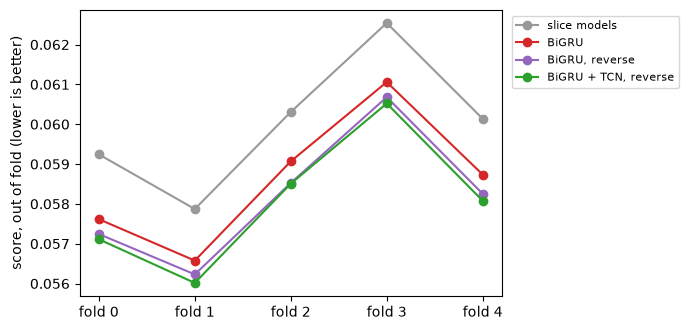

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(5)
for name, color in zip(SETUPS_5, ["0.6", "tab:red", "tab:purple", "tab:green"]):
    ax.plot(x, [score(y5[fold5 == k], p5[name][fold5 == k]) for k in range(5)], "o-", color=color, label=name)
ax.set_xticks(x, [f"fold {k}" for k in range(5)])
ax.set_ylabel("score, out of fold (lower is better)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 5.1 Key findings

- **On five folds the BiGRU scores 0.0586, 0.0014 better than the slice models and better on every fold.**
- **Reverse and the TCN keep their fold-0 gain on five folds,** on every fold: −0.0004 and −0.0001.

## 6. Setting the temperature

A temperature T rescales the logits, p = sigmoid(logit(p) / T): T < 1 makes the predictions more confident. By the rule, T is chosen on what a model was trained on: each of the 10 BiGRUs predicts its own training slices again and T minimises the loss there (`scripts/fit_temperature.py`). Fixed values (0.7 to 1.2) are shown for information only; they are not part of the pipeline. Out of fold:

T from the training folds: 0.981–0.991


T from the training folds − T = 1, out of fold: +0.0002 [+0.0002, +0.0003]


T = 1.2 − T = 1, out of fold: -0.0015 [-0.0017, -0.0013]


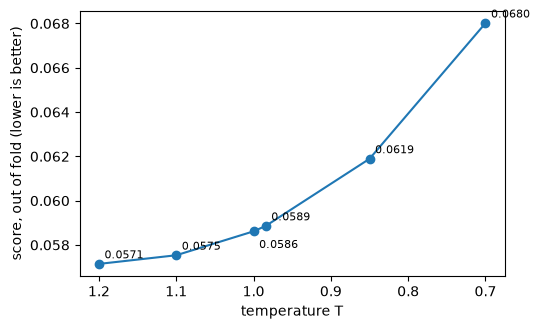

In [11]:
def sharpen(p, t):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return 1 / (1 + np.exp(-np.log(p / (1 - p)) / t))


def with_temperature(t_of):
    # The BiGRU setup of section 5 with temperature t_of(fold, b) on every model: out of fold (kept) and test.
    oof = np.zeros_like(p5["BiGRU"])
    for k in range(5):
        kk = pd.read_csv(FEATURES / cnn_run("convnext_tiny", k) / "oof_images.csv")["keep"].to_numpy()
        oof[fold5 == k] = np.mean([sharpen(np.mean([np.load(SEQ / f"is_{b}_logits_f{k}_s{s}" / "val_probs.npy")
                                                    for s in range(3)], 0)[kk], t_of(k, b)) for b in BACKBONES], 0)
    test = np.mean([sharpen(np.mean([np.load(SEQ / f"is_{b}_logits_f{k}_s{s}" / "test_probs.npy") for s in range(3)], 0),
                            t_of(k, b)) for k in range(5) for b in BACKBONES], 0)
    return oof, test


T_FIT = {(k, b): json.loads((SEQ / f"is_{b}_logits_f{k}_temperature.json").read_text())["T"]
         for k in range(5) for b in BACKBONES}
print(f"T from the training folds: {min(T_FIT.values()):.3f}–{max(T_FIT.values()):.3f}")
VARIANTS = {"1": lambda k, b: 1.0, "training folds": lambda k, b: T_FIT[(k, b)], "0.85": lambda k, b: 0.85,
            "0.7": lambda k, b: 0.7}
oof6, t6 = {}, {}
for name, t_of in VARIANTS.items():
    oof6[name], t6[name] = with_temperature(t_of)
print("T from the training folds − T = 1, out of fold:", interval(difference5(oof6["1"], oof6["training folds"])))
for t in (1.1, 1.2):  # above 1: out of fold only
    oof6[str(t)] = with_temperature(lambda k, b: t)[0]
print("T = 1.2 − T = 1, out of fold:", interval(difference5(oof6["1"], oof6["1.2"])))

t_values = [1.0, np.mean(list(T_FIT.values())), 0.85, 0.7]  # in the order of VARIANTS, also used in section 7
curve = sorted(zip(t_values + [1.1, 1.2], [score(y5, oof6[n]) for n in [*VARIANTS, "1.1", "1.2"]]))
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(*zip(*curve), "o-")
for t, v in curve:  # the label at T = 1 goes below its point, next to the one from the training folds
    ax.annotate(f"{v:.4f}", (t, v), xytext=(4, -12 if t == 1.0 else 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("temperature T")
ax.set_ylabel("score, out of fold (lower is better)")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

### 6.1 Key findings

- **The temperature from the training folds is 0.981–0.991:** each BiGRU is nearly calibrated on the slices it was trained on, and it costs 0.0002 out of fold.
- **Out of fold the BiGRUs are overconfident:** T = 1.2 gains 0.0015 (0.0586 → 0.0571), while every T below 1 is worse (0.0619 at 0.85, 0.0680 at 0.7). A likely reason: they learn from the slice models' outputs on their training folds, which are right more often than on new slices (section 1).

## 7. Predicting the test set

The final pipeline: one BiGRU per slice model of 04 on its logits (3 seeds), the temperature from its training folds, the mean of the 10 (`scripts/make_submission.py` writes the same file from these runs alone). No sequence augmentation, no TCN and no flip of the test images (each test slice also predicted mirrored left to right, the two averaged): their test gains are shown below.

In [12]:
final = t6["training folds"]
sample = pd.read_csv(DATA_DIR / "stage_2_sample_submission.csv")
submission = check_submission(to_submission(test_images, final), sample)
submission.to_csv(OUTPUTS / "submissions" / "05_seq10_bigru_T.csv.gz", index=False, float_format="%.6f")
print(f"05_seq10_bigru_T.csv.gz: {len(submission):,} rows | mean predicted any {final[:, -1].mean():.2%}")

05_seq10_bigru_T.csv.gz: 727,392 rows | mean predicted any 13.59%


The 22 late submissions of this notebook, with the slice models of 04 and the final leaderboard of 2019 for scale:

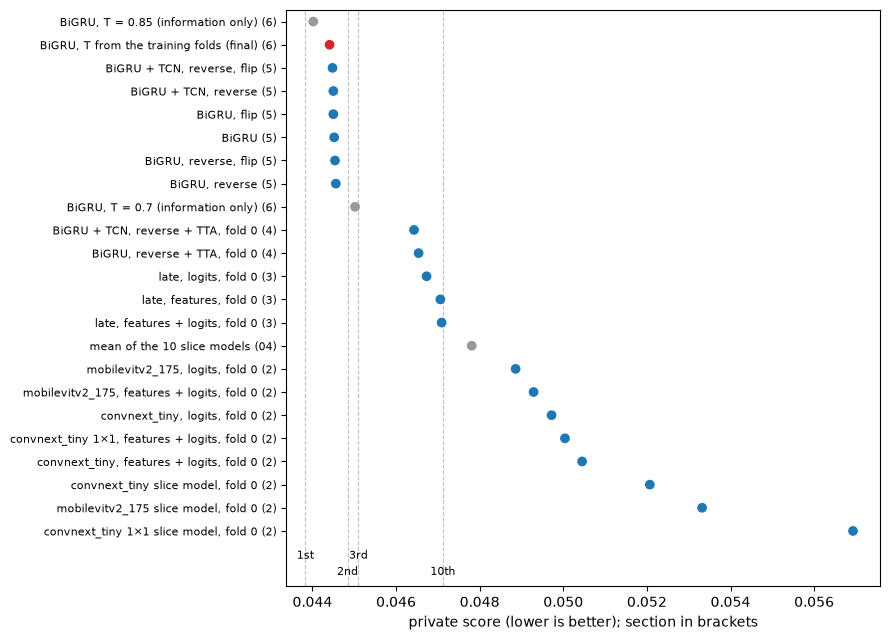

In [13]:
SUBMITTED = [  # (section, submission, private score); fold 0 = the fold-0 models alone
    (2, "convnext_tiny slice model, fold 0", 0.05207), (2, "convnext_tiny, logits, fold 0", 0.04972),
    (2, "convnext_tiny, features + logits, fold 0", 0.05045), (2, "mobilevitv2_175 slice model, fold 0", 0.05332),
    (2, "mobilevitv2_175, logits, fold 0", 0.04886), (2, "mobilevitv2_175, features + logits, fold 0", 0.04929),
    (2, "convnext_tiny 1×1 slice model, fold 0", 0.05693), (2, "convnext_tiny 1×1, features + logits, fold 0", 0.05004),
    (3, "late, logits, fold 0", 0.04673), (3, "late, features, fold 0", 0.04706), (3, "late, features + logits, fold 0", 0.04709),
    (4, "BiGRU, reverse + TTA, fold 0", 0.04654), (4, "BiGRU + TCN, reverse + TTA, fold 0", 0.04643),
    (5, "BiGRU", 0.04452), (5, "BiGRU, flip", 0.04450), (5, "BiGRU, reverse", 0.04456), (5, "BiGRU, reverse, flip", 0.04454),
    (5, "BiGRU + TCN, reverse", 0.04450), (5, "BiGRU + TCN, reverse, flip", 0.04448),
    (6, "BiGRU, T from the training folds (final)", 0.04441), (6, "BiGRU, T = 0.85 (information only)", 0.04402),
    (6, "BiGRU, T = 0.7 (information only)", 0.04502)]
assert len(SUBMITTED) == 22
s = pd.DataFrame(SUBMITTED + [(4.5, "mean of the 10 slice models (04)", 0.04781)],
                 columns=["section", "submission", "private"]).sort_values("private", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = ["tab:red" if "final" in n else "0.6" if "04" in n or "information" in n else "tab:blue" for n in s["submission"]]
ax.scatter(s["private"], np.arange(len(s)), c=colors, zorder=3)
for i, (place, v) in enumerate({"1st": 0.04383, "2nd": 0.04484, "3rd": 0.04510, "10th": 0.04712}.items()):
    ax.axvline(v, color="0.75", ls="--", lw=0.8)
    ax.text(v, -1.2 - 0.7 * (i % 2), place, fontsize=8, ha="center")
ax.set_ylim(-2.4, len(s) - 0.5)
ax.set_yticks(np.arange(len(s)), [f"{n} ({sec:g})" if sec != 4.5 else n for sec, n in zip(s["section"], s["submission"])],
              fontsize=8)
ax.set_xlabel("private score (lower is better); section in brackets")
plt.tight_layout()
plt.show()

Two of these comparisons in detail: the private score of the BiGRU against the temperature (section 6), and the test gain of reverse and the TCN (section 4) with the fold-0 models alone and with all 10 models (section 5):

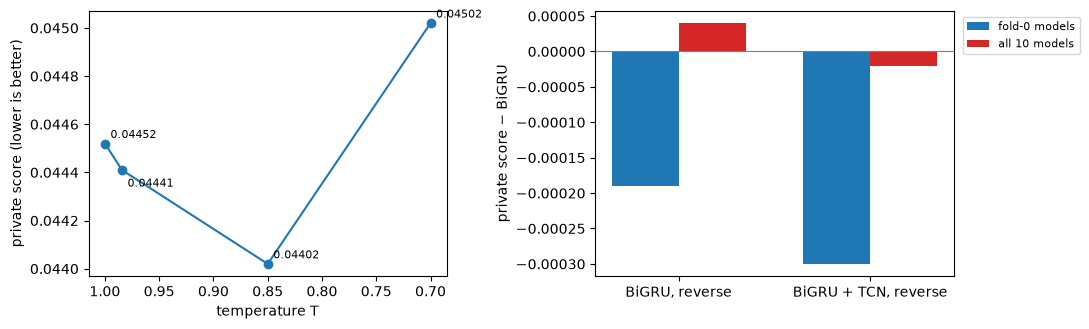

In [14]:
private = {n: v for _, n, v in SUBMITTED}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
t_private = [private["BiGRU"], private["BiGRU, T from the training folds (final)"],
             private["BiGRU, T = 0.85 (information only)"], private["BiGRU, T = 0.7 (information only)"]]
axes[0].plot(t_values, t_private, "o-")
for i, (t, v) in enumerate(zip(t_values, t_private)):  # the label of the second point near T = 1 goes below it
    axes[0].annotate(f"{v:.5f}", (t, v), xytext=(4, -12 if i == 1 else 4), textcoords="offset points", fontsize=8)
axes[0].set_xlabel("temperature T")
axes[0].set_ylabel("private score (lower is better)")
axes[0].invert_xaxis()

gains = {"BiGRU, reverse": (private["BiGRU, reverse + TTA, fold 0"] - private["late, logits, fold 0"],
                            private["BiGRU, reverse"] - private["BiGRU"]),
         "BiGRU + TCN, reverse": (private["BiGRU + TCN, reverse + TTA, fold 0"] - private["late, logits, fold 0"],
                                  private["BiGRU + TCN, reverse"] - private["BiGRU"])}
w = 0.35
for i, (label, color) in enumerate([("fold-0 models", "tab:blue"), ("all 10 models", "tab:red")]):
    axes[1].bar(np.arange(2) + (i - 0.5) * w, [g[i] for g in gains.values()], w, color=color, label=label)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_xticks(np.arange(2), list(gains))
axes[1].set_ylabel("private score − BiGRU")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 7.1 Key findings

- **The final file scores 0.04441,** between the 1st (0.04383) and the 2nd place (0.04484) of 2019, and 0.0034 better than the slice models of 04 (0.04781).
- **The test confirms the input and the late ensemble:** with the fold-0 models alone, the sequence model on the logits beats the slice model by 0.0024 (convnext_tiny) and 0.0045 (mobilevitv2_175), more than out of fold, and the late ensemble of the logits models (0.04673) beats those of the vector (0.04706, 0.04709).
- **Reverse and the TCN gain on test with the fold-0 models alone, not beyond noise with all 10:** 0.04673 → 0.04654 → 0.04643 on fold 0, but 0.04456 and 0.04450 against 0.04452 on five folds. A likely reason: both reduce the variance of a single model, which the mean of the 10 models already does; out of fold every slice is predicted by the models of one fold, so it cannot show that. The flip of the test images changes the score by 0.00002.
- **The test rewards more confident predictions than out of fold does:** the temperature from the training folds gains 0.00011 (0.04452 → 0.04441), a fixed T = 0.85 reaches 0.04402 although out of fold every T below 1 is worse and T = 1.2 gains 0.0015, and 0.7 goes too far (0.04502). A likely reason: three readers labelled the test set, one the train set.
- **Out of fold and test disagree once more:** convnext_tiny with the vector is worse than its slice model out of fold but better on test (0.05045 against 0.05207).
- On features + logits the 1×1 slice model with the sequence model beats 3×1 on test too (0.05004 against 0.05045), but not 3×1 on the logits alone (0.04972).

## Summary

- **Held-out fold rule:** each sequence model learns from its slice model's outputs on that model's own four training folds and is scored on the fifth; nothing inside a run (epoch, temperature) is chosen on its scored fold. The design was screened on fold 0, as in 04.
- **Choices made** (late ensemble of the two backbones unless noted; the gap of the other options to the chosen one):

  | Question | Tested | Chosen | Other options |
  |---|---|---|---|
  | input from the slice model | logits, features, both; projection 128 / 256 / 512; two branches | the six logits | the vector, on any path: +0.0008 to +0.0014 (convnext_tiny), +0.0002 to +0.0004 (mobilevitv2_175) |
  | 3×1 or 1×1 slice model | convnext_tiny, sequence model on features + logits | 3×1 | 1×1 better there (−0.0020) and on test, but behind 3×1 with the logits on test; exists only for fold 0 |
  | two backbones | early (one model on both), late (mean of two) | late | early +0.0060 |
  | sequence network | BiGRU, BiLSTM, TCN, transformer | BiGRU | TCN +0.0000, BiLSTM +0.0003, transformer +0.0005 |
  | augmentation | reverse, subsample, both; reverse TTA | none (section 5) | reverse −0.0004 on fold 0, no gain on test with five folds |

- **Five folds:** the BiGRU scores 0.0586 out of fold, 0.0014 better than the slice models and better on every fold.
- **Test set:** 0.04452 for the mean of the 10 BiGRUs, 0.04441 with the temperature from their training folds (from 0.04781 for the slice models of 04). With a fixed T = 0.85 the score is 0.04402: the test rewards more confident predictions, while out of fold the BiGRUs are overconfident (T = 1.2 gains 0.0015 there).

**Limits**
- The private score decided several steps (augmentation, the second network, the setup of section 7), with 22 late submissions in this notebook. It served as a development set, so the final score is somewhat optimistic for a model chosen once.
- The design was screened on fold 0, which is also one of the five folds of section 5, so the five-fold out-of-fold score is slightly optimistic.
- The settings of the networks and augmentations (sizes, the learning rate of the transformer, the probabilities of the augmentations) were fixed once, not tuned.
- The out-of-fold score uses single-reader labels and one fold model per slice: it does not see the effect of averaging the fold models on test, nor the calibration the test labels reward (section 7).
- The slice models fit their training folds better than new slices (section 1); the sequence models learn from those outputs, and that this helps on test depends on the test labels.